# Application et visualisation — le cas séparable

**SVM à marge dure : un problème d'optimisation sous contraintes**
Cette partie fait tourner tout cela. Nous allons :

1. résoudre le primal directement
2. vérifier numériquement les hypothèses
3. résoudre le dual, et constater que les deux donnent exactement la même solution, c'est la dualité forte
4. lire l'écart complémentaire pour identifier les vecteurs de support
5. visualiser la marge, et démontrer que seuls les vecteurs de support la déterminent.

In [1]:
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

POS, NEG = "#2b6cb0", "#dd6b20"
REGION = ListedColormap(["#f6ddcb", "#d6e3f1"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(precision=4, suppress=True)

## 1. Des données linéairement séparables

Deux nuages bien distincts, étiquetés $y_i \in \{-1, +1\}$. On reste en dimension 2
pour pouvoir tout dessiner. Quarante points : assez pour que le résultat soit parlant,
assez peu pour qu'on puisse les compter à l'œil.

n = 40 points en dimension 2
classe +1 : 20 points   |   classe -1 : 20 points


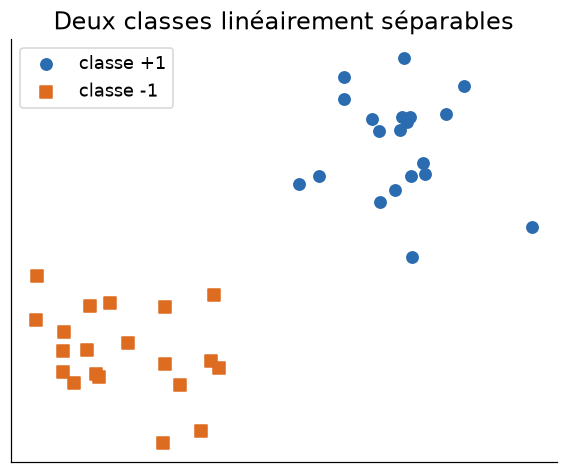

In [2]:
X, y = make_blobs(n_samples=40, centers=[[-2.0, -1.6], [2.0, 1.6]],
                  cluster_std=0.9, random_state=1)
y = np.where(y == 0, -1, 1).astype(float)
n, d = X.shape

print("n = %d points en dimension %d" % (n, d))
print("classe +1 : %d points   |   classe -1 : %d points"
      % ((y == 1).sum(), (y == -1).sum()))

fig, ax = plt.subplots(figsize=(6.4, 5))
ax.scatter(X[y == 1, 0],  X[y == 1, 1],  c=POS, s=55, label="classe +1")
ax.scatter(X[y == -1, 0], X[y == -1, 1], c=NEG, s=55, marker="s", label="classe -1")
ax.legend(fontsize=12); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Deux classes linéairement séparables")
plt.show()

## 2. Le problème primal, écrit tel quel

Les $n$ contraintes sont écrites en **une seule ligne** de code : `cp.multiply(y, X @ w + b) >= 1`
est un vecteur d'inégalités, une par point.

Deux remarques sur le rôle de la contrainte :

- Sans elle, $w = 0$ minimise l'objectif, et on ne classe plus rien. C'est la contrainte qui
  relie l'objectif aux données.
- Elle demande deux choses à la fois : que le point soit **du bon côté** (le signe de
  $w^\top x_i + b$ est celui de $y_i$) et qu'il soit à **au moins une marge** de la frontière
  (la valeur absolue vaut au moins 1).

In [3]:
w = cp.Variable(d)
b = cp.Variable()

objectif    = cp.Minimize(0.5 * cp.sum_squares(w))
contraintes = [cp.multiply(y, X @ w + b) >= 1]     # n contraintes d'un coup

primal = cp.Problem(objectif, contraintes)
primal.solve(solver=cp.CLARABEL, tol_gap_abs=1e-12, tol_gap_rel=1e-12, tol_feas=1e-12)

w_p, b_p = w.value, float(b.value)

print("statut :", primal.status)
print("valeur optimale du primal : %.6f" % primal.value)
print("w =", w_p)
print("b = %.4f" % b_p)
print("largeur de la marge  2/||w|| = %.4f" % (2 / np.linalg.norm(w_p)))

statut : optimal
valeur optimale du primal : 0.358588
w = [0.5531 0.6413]
b = -0.1222
largeur de la marge  2/||w|| = 2.3617


## 3. Les hypothèses, vérifiées numériquement

In [4]:
print("valeurs propres de la hessienne de 0.5*||w||^2 :", np.linalg.eigvalsh(np.eye(d)))
print("-> strictement positives : objectif strictement convexe\n")

cout     = lambda ww: 0.5 * ww @ ww
faisable = lambda ww, bb: bool((y * (X @ ww + bb) >= 1 - 1e-9).all())

# un second point admissible, volontairement différent de l'optimum
wB_, bB_ = cp.Variable(d), cp.Variable()
cp.Problem(cp.Minimize(0.5 * cp.sum_squares(wB_)),
           [cp.multiply(y, X @ wB_ + bB_) >= 1,
            wB_[0] >= w_p[0] + 0.4]).solve(solver=cp.CLARABEL)
wA, bA = w_p, b_p
wB, bB = wB_.value, float(bB_.value)
wM, bM = 0.5 * (wA + wB), 0.5 * (bA + bB)

print("A admissible :", faisable(wA, bA), "   B admissible :", faisable(wB, bB))
print("milieu de [A, B] admissible :", faisable(wM, bM),
      "  -> l'ensemble admissible est convexe\n")
print("cout(milieu)            = %.6f" % cout(wM))
print("moyenne cout(A),cout(B) = %.6f" % (0.5 * (cout(wA) + cout(wB))))
print("-> inegalite stricte : la fonction est strictement convexe,")
print("   donc le minimum est unique. Et cout(A) = %.6f est le plus petit." % cout(wA))

valeurs propres de la hessienne de 0.5*||w||^2 : [1. 1.]
-> strictement positives : objectif strictement convexe

A admissible : True    B admissible : True
milieu de [A, B] admissible : True   -> l'ensemble admissible est convexe

cout(milieu)            = 0.421488
moyenne cout(A),cout(B) = 0.448228
-> inegalite stricte : la fonction est strictement convexe,
   donc le minimum est unique. Et cout(A) = 0.358588 est le plus petit.


## 4. Le dual

On pose $H = (y y^\top) \circ K$ avec $K$ la matrice de Gram, de sorte que le terme quadratique
s'écrive $\alpha^\top H \alpha$.

In [5]:
K = X @ X.T             # matrice de Gram : K[i,j] = <x_i, x_j>
H = np.outer(y, y) * K  # H[i,j] = y_i y_j <x_i, x_j>

vp = np.linalg.eigvalsh(H)
print("H est symétrique :", np.allclose(H, H.T))
print("valeur propre minimale de H : %.2e  (nulle à la précision machine)" % vp.min())
print("-> H est semi-définie positive, donc le dual est concave :")
print("   son maximum est global, pas seulement local.")

H est symétrique : True
valeur propre minimale de H : -7.27e-14  (nulle à la précision machine)
-> H est semi-définie positive, donc le dual est concave :
   son maximum est global, pas seulement local.


In [6]:
alpha = cp.Variable(n)

dual = cp.Problem(
    cp.Maximize(cp.sum(alpha) - 0.5 * cp.quad_form(alpha, cp.psd_wrap(H))),
    [alpha >= 0,            # multiplicateurs d'inégalité : positifs
     y @ alpha == 0])       # vient de la dérivée en b

dual.solve(solver=cp.CLARABEL, max_iter=200000,
           tol_gap_abs=1e-12, tol_gap_rel=1e-12, tol_feas=1e-12)

a = np.asarray(alpha.value).ravel()
a[a < 1e-7] = 0.0            # nettoyage numérique

print("statut :", dual.status)
print("valeur optimale du dual : %.6f" % dual.value)

statut : optimal
valeur optimale du dual : 0.358588


## 5. Dualité forte : les deux problèmes se rejoignent

Le primal est convexe et ses contraintes sont affines : la condition de Slater est satisfaite,
donc il n'y a **pas de saut de dualité**. Les deux valeurs optimales doivent coïncider, et
$w$ reconstruit à partir des $\alpha$ doit redonner exactement le $w$ du primal.

C'est vérifiable à la machine, et c'est le point le plus convaincant de cette partie :
deux problèmes d'apparence très différente, résolus séparément, donnent le même objet.

In [7]:
w_d = (a * y) @ X  
# w = somme alpha_i y_i x_i

# b : un point dont alpha > 0 vérifie y_i (w.x_i + b) = 1 exactement
sv = a > 0
b_d = float(np.mean(y[sv] - X[sv] @ w_d))

print("valeur primale : %.8f" % primal.value)
print("valeur duale   : %.8f" % dual.value)
print("saut de dualité : %.2e        <- nul\n" % abs(primal.value - dual.value))

print("w (primal) =", w_p)
print("w (dual)   =", w_d)
print("||w_primal - w_dual|| = %.2e" % np.linalg.norm(w_p - w_d))
print("|b_primal - b_dual|   = %.2e" % abs(b_p - b_d))

valeur primale : 0.35858827
valeur duale   : 0.35858827
saut de dualité : 4.90e-14        <- nul

w (primal) = [0.5531 0.6413]
w (dual)   = [0.5531 0.6413]
||w_primal - w_dual|| = 7.76e-14
|b_primal - b_dual|   = 4.57e-14


## 6. L'écart complémentaire désigne les vecteurs de support

La condition d'écart complémentaire s'écrit, pour chaque point,

$$\alpha_i\,\big[\,y_i(w^\top x_i + b) - 1\,\big] = 0$$

C'est un produit nul : **au moins un des deux facteurs** doit s'annuler. Dans le cas séparable
il n'y a donc que deux situations possibles, et aucune autre :

- $\alpha_i = 0$ et $y_i(w^\top x_i + b) > 1$ — le point est strictement au-delà de la marge.
  Il ne contribue pas à $w$.
- $\alpha_i > 0$ et $y_i(w^\top x_i + b) = 1$ — le point est **exactement sur** le bord de la
  marge. C'est un **vecteur de support**.

Un point ne peut pas être à la fois loin de la frontière et porteur d'un multiplicateur non nul.

In [8]:
marge_fonctionnelle = y * (X @ w_p + b_p)      # y_i f(x_i)

print(" i   alpha_i     y_i f(x_i)    produit alpha*(yf-1)")
print("-" * 54)
for i in np.argsort(-a)[:8]:                    # les 8 plus grands alpha
    print("%2d   %8.4f    %8.4f       %.2e"
          % (i, a[i], marge_fonctionnelle[i], a[i] * (marge_fonctionnelle[i] - 1)))
print("...")
print("\nvecteurs de support (alpha > 0) : %d sur %d" % (sv.sum(), n))
print("leur marge fonctionnelle vaut :", marge_fonctionnelle[sv].round(6))
print("marge minimale des autres points : %.4f"
      % marge_fonctionnelle[~sv].min())

 i   alpha_i     y_i f(x_i)    produit alpha*(yf-1)
------------------------------------------------------
35     0.3586      1.0000       2.79e-15
 8     0.2825      1.0000       2.57e-15
11     0.0761      1.0000       8.95e-16
 0     0.0000      2.6754       0.00e+00
 4     0.0000      3.3173       0.00e+00
 5     0.0000      2.1417       0.00e+00
 2     0.0000      3.0844       0.00e+00
 1     0.0000      2.2920       0.00e+00
...

vecteurs de support (alpha > 0) : 3 sur 40
leur marge fonctionnelle vaut : [1. 1. 1.]
marge minimale des autres points : 1.2397


## 7. La visualisation

On trace les trois droites $w^\top x + b = -1,\ 0,\ +1$. La frontière est au milieu, et les
deux bords de la marge passent exactement par les vecteurs de support.

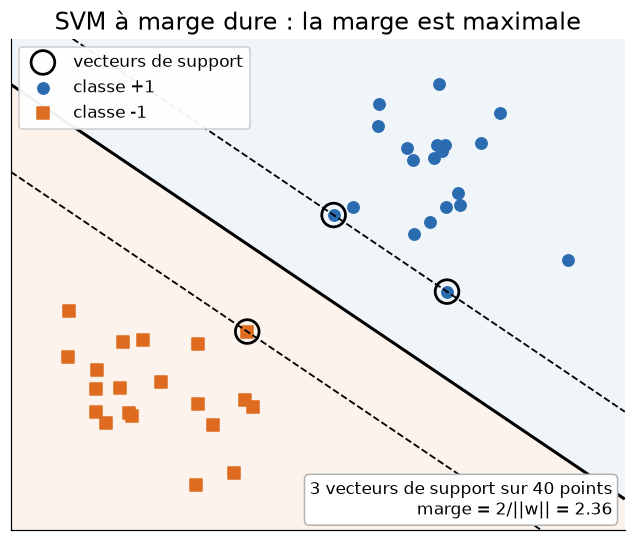

In [9]:
def bornes_de(X, pad=0.8):
    return (X[:, 0].min() - pad, X[:, 0].max() + pad,
            X[:, 1].min() - pad, X[:, 1].max() + pad)


def tracer(w_, b_, support, X, y, ax, titre, bornes=None):
    # bornes communes = deux panneaux comparables à l'oeil
    x0, x1, y0, y1 = bornes if bornes is not None else bornes_de(X)
    xx, yy = np.meshgrid(np.linspace(x0, x1, 400), np.linspace(y0, y1, 400))
    Z = (np.c_[xx.ravel(), yy.ravel()] @ w_ + b_).reshape(xx.shape)

    ax.contourf(xx, yy, np.sign(Z), levels=[-2, 0, 2], cmap=REGION, alpha=0.35)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[1.2, 2, 1.2])
    ax.scatter(X[support, 0], X[support, 1], s=240, facecolors="none",
               edgecolors="k", linewidths=1.8, label="vecteurs de support")
    ax.scatter(X[y == 1, 0],  X[y == 1, 1],  c=POS, s=55, label="classe +1")
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c=NEG, s=55, marker="s", label="classe -1")
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)


fig, ax = plt.subplots(figsize=(7.2, 5.8))
tracer(w_p, b_p, sv, X, y, ax, "SVM à marge dure : la marge est maximale")
ax.legend(loc="upper left", fontsize=11, framealpha=0.95)
ax.text(0.98, 0.02, "%d vecteurs de support sur %d points\nmarge = 2/||w|| = %.2f"
        % (sv.sum(), n, 2 / np.linalg.norm(w_p)),
        transform=ax.transAxes, ha="right", va="bottom", fontsize=11,
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
plt.show()

## 8. La démonstration : seuls les vecteurs de support comptent

C'est la conséquence la plus frappante de l'écart complémentaire. Puisque
$w = \sum_i \alpha_i y_i x_i$ et que $\alpha_i = 0$ partout ailleurs, la solution ne dépend
**que** des vecteurs de support.

Vérifions-le sans rien supposer : on jette les 37 autres points, on résout le problème
depuis zéro sur les 3 qui restent, et on compare.

In [10]:
X_sv, y_sv = X[sv], y[sv]

w3, b3 = cp.Variable(d), cp.Variable()
pb3 = cp.Problem(cp.Minimize(0.5 * cp.sum_squares(w3)),
                 [cp.multiply(y_sv, X_sv @ w3 + b3) >= 1])
pb3.solve(solver=cp.CLARABEL, tol_gap_abs=1e-12, tol_gap_rel=1e-12, tol_feas=1e-12)

print("problème résolu sur %d points au lieu de %d" % (sv.sum(), n))
print("w (40 points) =", w_p)
print("w ( 3 points) =", w3.value)
print("\n||difference|| = %.2e" % np.linalg.norm(w3.value - w_p))
print("|difference b| = %.2e" % abs(float(b3.value) - b_p))
print("\n-> rigoureusement la même frontière.")

problème résolu sur 3 points au lieu de 40
w (40 points) = [0.5531 0.6413]
w ( 3 points) = [0.5531 0.6413]

||difference|| = 4.67e-14
|difference b| = 1.71e-15

-> rigoureusement la même frontière.


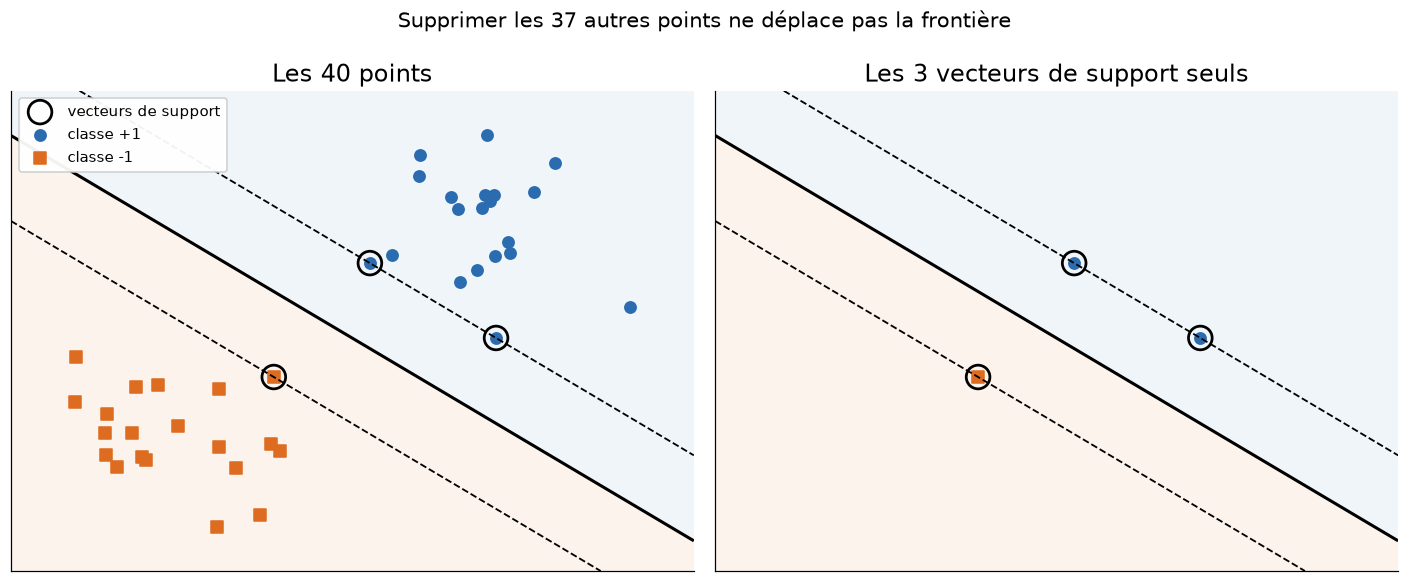

In [11]:
cadre = bornes_de(X)             # le meme cadre pour les deux panneaux

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
tracer(w_p, b_p, sv, X, y, axes[0], "Les 40 points", bornes=cadre)
tracer(w3.value, float(b3.value), np.ones(sv.sum(), dtype=bool),
       X_sv, y_sv, axes[1], "Les 3 vecteurs de support seuls", bornes=cadre)
axes[0].legend(loc="upper left", fontsize=10, framealpha=0.95)
fig.suptitle("Supprimer les 37 autres points ne déplace pas la frontière", fontsize=14)
fig.tight_layout()
plt.show()

À l'inverse, déplacer **un seul** vecteur de support déplace la frontière : ce sont bien
eux, et eux seuls, qui la portent.

In [12]:
X_mod = X.copy()
i_sv = np.where(sv)[0][0]
X_mod[i_sv] = X_mod[i_sv] + np.array([0.0, 1.2])      # on pousse un VS

w4, b4 = cp.Variable(d), cp.Variable()
pb4 = cp.Problem(cp.Minimize(0.5 * cp.sum_squares(w4)),
                 [cp.multiply(y, X_mod @ w4 + b4) >= 1])
pb4.solve(solver=cp.CLARABEL)

print("on déplace le vecteur de support n°%d de 1.2 vers le haut" % i_sv)
print("||w_nouveau - w_ancien|| = %.4f   <- la frontière a bougé"
      % np.linalg.norm(w4.value - w_p))
print("nouvelle marge = %.4f  (avant : %.4f)"
      % (2 / np.linalg.norm(w4.value), 2 / np.linalg.norm(w_p)))

on déplace le vecteur de support n°8 de 1.2 vers le haut
||w_nouveau - w_ancien|| = 0.1344   <- la frontière a bougé
nouvelle marge = 2.5713  (avant : 2.3617)


## 9. Validation

Enfin, on compare à `scikit-learn`, qui résout le même problème par l'algorithme SMO.
Un très grand `C` reproduit la marge dure, puisqu'il rend toute violation prohibitive.

In [13]:
sk = SVC(C=1e6, kernel="linear", tol=1e-10).fit(X, y)

print("||w_nous - w_sklearn|| = %.2e" % np.linalg.norm(w_p - sk.coef_.ravel()))
print("|b_nous - b_sklearn|   = %.2e" % abs(b_p - sk.intercept_[0]))
print("vecteurs de support : nous = %d, sklearn = %d" % (sv.sum(), sk.support_.size))
print("mêmes indices :", sorted(np.where(sv)[0]) == sorted(sk.support_))

||w_nous - w_sklearn|| = 9.72e-09
|b_nous - b_sklearn|   = 9.43e-09
vecteurs de support : nous = 3, sklearn = 3
mêmes indices : True


## Ce qu'il faut retenir

1. Le primal et le dual, résolus séparément, donnent **exactement** la même frontière :
   c'est la dualité forte, et elle est vérifiable à la machine.
2. La contrainte $y_i(w^\top x_i + b) \ge 1$ n'est pas accessoire. Sans elle, $w = 0$ gagne.
   C'est elle qui définit la marge.
3. L'écart complémentaire partage les points en deux, sans cas intermédiaire : multiplicateur
   nul et point loin de la frontière, ou multiplicateur positif et point sur le bord.
4. Conséquence : **3 points sur 40** suffisent à reconstruire la solution. On peut jeter les
   37 autres et retrouver la même droite au dixième de milliardième près.